[1] samples: train 1849 | val 516 | test 635
    evaluation self-checks passed (exact hit = 100 %, two beams off = 60 % DBA)

[3] kNN: k = 25 chosen on validation DBA

[4] GRU baseline: hidden 64, lr 0.001, batch 32, up to 200 epochs, 5 seeds
    seed 0: best epoch 190 | test top-1 34.0 | top-3 72.1 | DBA 83.4
    seed 1: best epoch 167 | test top-1 36.1 | top-3 73.5 | DBA 83.2
    seed 2: best epoch 129 | test top-1 34.3 | top-3 73.4 | DBA 83.1
    seed 3: best epoch 125 | test top-1 34.3 | top-3 75.0 | DBA 83.2
    seed 4: best epoch 186 | test top-1 35.0 | top-3 71.3 | DBA 83.5

[5] TEST DRIVES (635 samples)
model                                            top-1 %       top-3 %       top-5 %    +-1 beam %       power %         DBA %
floor: always beam 16                               11.3          14.5          17.2          21.6          74.0          28.8
kNN on GPS position (k=25)                          34.3          70.7          82.2          69.4          95.3          82.9


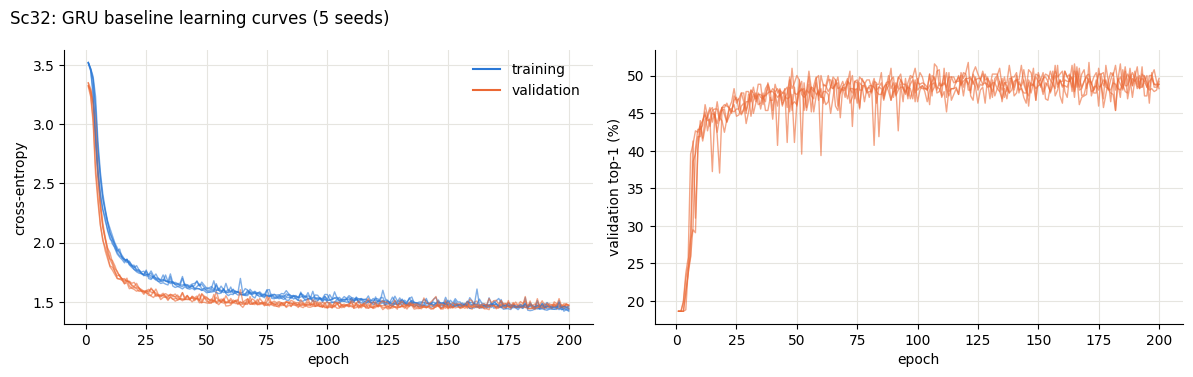


saved in S32/: S3_report.txt, S3_results.csv, S3_curves.png


In [1]:
# ==== S3: ONE EVALUATION FOR EVERY MODEL + THE CHALLENGE PAPER'S BASELINE (Charan et al., arXiv:2209.07519)
# run in the ODT folder, after S2. needs: numpy, pandas, matplotlib, torch (CPU is enough: a few minutes)
import os, sys, argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn

ap = argparse.ArgumentParser()
ap.add_argument("--scen", default="32")
ap.add_argument("--seeds", type=int, default=5)
ap.add_argument("--hidden", type=int, default=64)
ap.add_argument("--epochs", type=int, default=200)
ap.add_argument("--lr", type=float, default=1e-3)
ap.add_argument("--batch", type=int, default=32)
A = ap.parse_args([])   # notebook: settings are the defaults above
D = f"S{A.scen}"


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S3_report.txt"))

# ------------------------------------------------------------------ 1. the evaluation (used by every model from now on)
def evaluate(scores, beam, power, delta=5, K=3):
    """scores (n, 64) higher = better; beam (n,) true best beam 0..63; power (n, 64) measured beam powers"""
    rank = np.argsort(-scores, 1); b = np.asarray(beam); err = rank[:, 0] - b
    Y = [1 - np.mean(np.min(np.minimum(np.abs(rank[:, :k] - b[:, None]) / delta, 1), 1)) for k in range(1, K + 1)]
    return dict(top1=100 * np.mean(err == 0), top3=100 * np.mean((rank[:, :3] == b[:, None]).any(1)),
                top5=100 * np.mean((rank[:, :5] == b[:, None]).any(1)), within1=100 * np.mean(np.abs(err) <= 1),
                power=100 * np.mean(power[np.arange(len(b)), rank[:, 0]] / np.maximum(power.max(1), 1e-12)),
                dba=100 * np.mean(Y))


S = np.load(os.path.join(D, "S2_samples.npz"), allow_pickle=True)   # split was saved as text
split, beam, power, pos = S["split"].astype(str), S["beam"], S["power"].astype(np.float64), S["pos"]
idx = {nm: np.flatnonzero(split == nm) for nm in ("train", "val", "test")}
print(f"[1] samples: train {len(idx['train'])} | val {len(idx['val'])} | test {len(idx['test'])}")
one = np.zeros((1, 64)); one[0, 3] = 1
chk = evaluate(one, np.array([3]), np.ones((1, 64)))
assert chk["top1"] == 100 and chk["dba"] == 100, "evaluation self-check failed"
two = -np.ones((1, 64)); two[0, [5, 9, 10]] = [3, 2, 1]   # guesses 5, 9, 10 for true beam 3
assert abs(evaluate(two, np.array([3]), np.ones((1, 64)))["dba"] - 60) < 1e-9, "DBA self-check failed"   # best guess 2 beams off: 1 - 2/5 = 0.6 at every K
print("    evaluation self-checks passed (exact hit = 100 %, two beams off = 60 % DBA)")
RES = []

# ------------------------------------------------------------------ 2. floor: most common training beam
mc = np.bincount(beam[idx["train"]], minlength=64).argmax()
sc = np.zeros((len(idx["test"]), 64)); sc[:, mc] = 1
RES.append(dict(model=f"floor: always beam {mc}", seed=0, **evaluate(sc, beam[idx["test"]], power[idx["test"]])))

# ------------------------------------------------------------------ 3. kNN on the normalised GPS positions
Xf = pos.reshape(len(pos), -1)


def knn_scores(tr, rows, k):
    d = ((Xf[rows][:, None] - Xf[tr][None]) ** 2).sum(-1)
    nb = np.argsort(d, 1)[:, :k]
    out = np.zeros((len(rows), 64))
    for j in range(k):
        np.add.at(out, (np.arange(len(rows)), beam[tr][nb[:, j]]), 1.0 / (j + 1))
    return out


ks = [1, 3, 5, 9, 15, 25]
kb = max(ks, key=lambda k: evaluate(knn_scores(idx["train"], idx["val"], k), beam[idx["val"]], power[idx["val"]])["dba"])
RES.append(dict(model=f"kNN on GPS position (k={kb})", seed=0,
                **evaluate(knn_scores(idx["train"], idx["test"], kb), beam[idx["test"]], power[idx["test"]])))
print(f"\n[3] kNN: k = {kb} chosen on validation DBA")

# ------------------------------------------------------------------ 4. the paper's baseline: two-stage GRU on 2 GPS positions
class GRUBase(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.gru = nn.GRU(2, h, num_layers=2, batch_first=True)
        self.fc = nn.Linear(h, 64)

    def forward(self, x):                                  # x (B, 2 steps, 2 coordinates)
        o, _ = self.gru(x)
        return self.fc(o[:, -1])


X = torch.tensor(pos, dtype=torch.float32); Y = torch.tensor(beam, dtype=torch.long)
curves = []
print(f"\n[4] GRU baseline: hidden {A.hidden}, lr {A.lr}, batch {A.batch}, up to {A.epochs} epochs, {A.seeds} seeds")
for seed in range(A.seeds):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = GRUBase(A.hidden); opt = torch.optim.Adam(net.parameters(), lr=A.lr)
    best, hist = (np.inf, None, 0), []
    for ep in range(A.epochs):
        net.train(); order = rng.permutation(idx["train"])
        for i in range(0, len(order), A.batch):
            b = order[i:i + A.batch]
            loss = Fn.cross_entropy(net(X[b]), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            lt = Fn.cross_entropy(net(X[idx["train"]]), Y[idx["train"]]).item()
            lv_lg = net(X[idx["val"]]); lv = Fn.cross_entropy(lv_lg, Y[idx["val"]]).item()
        hist.append((ep + 1, lt, lv, evaluate(lv_lg.numpy(), beam[idx["val"]], power[idx["val"]])["top1"]))
        if lv < best[0]:
            best = (lv, {k: v.clone() for k, v in net.state_dict().items()}, ep + 1)
    net.load_state_dict(best[1]); net.eval(); curves.append(hist)
    with torch.no_grad():
        r = evaluate(net(X[idx["test"]]).numpy(), beam[idx["test"]], power[idx["test"]])
    RES.append(dict(model="GRU baseline (paper, 2 GPS positions)", seed=seed, best_epoch=best[2], **r))
    print(f"    seed {seed}: best epoch {best[2]} | test top-1 {r['top1']:.1f} | top-3 {r['top3']:.1f} | DBA {r['dba']:.1f}")

# ------------------------------------------------------------------ 5. report
R = pd.DataFrame(RES); R.to_csv(os.path.join(D, "S3_results.csv"), index=False)
cols = ["top1", "top3", "top5", "within1", "power", "dba"]
print(f"\n[5] TEST DRIVES ({len(idx['test'])} samples)")
print(f"{'model':42s}" + "".join(f"{c:>14s}" for c in ["top-1 %", "top-3 %", "top-5 %", "+-1 beam %", "power %", "DBA %"]))
for name in R["model"].unique():
    q = R[R["model"] == name]
    if len(q) > 1:
        print(f"{name:42s}" + "".join(f"{q[c].mean():8.1f} +-{q[c].std(ddof=0):3.1f}" for c in cols))
    else:
        print(f"{name:42s}" + "".join(f"{q[c].iloc[0]:14.1f}" for c in cols))
print(f"{'paper (random split, Sc32-34)':42s}{26.7:14.1f}{53.4:14.1f}{'':>14s}{'':>14s}{'':>14s}{'~65':>14s}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for h in curves:
    h = np.array(h)
    ax[0].plot(h[:, 0], h[:, 1], color="#2a78d6", lw=1, alpha=0.6); ax[0].plot(h[:, 0], h[:, 2], color="#eb6834", lw=1, alpha=0.6)
    ax[1].plot(h[:, 0], h[:, 3], color="#eb6834", lw=1, alpha=0.6)
ax[0].plot([], [], color="#2a78d6", label="training"); ax[0].plot([], [], color="#eb6834", label="validation"); ax[0].legend(frameon=False)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation top-1 (%)")
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False); a_.grid(color="#e6e5e0", lw=0.8)
fig.suptitle(f"Sc{A.scen}: GRU baseline learning curves ({A.seeds} seeds)", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(os.path.join(D, "S3_curves.png"), dpi=140); plt.show()
print(f"\nsaved in {D}/: S3_report.txt, S3_results.csv, S3_curves.png")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o